
# VGG Architectures on CIFAR-10

## Project Objective

The main aim of this project is to study how the depth of a Convolutional Neural Network affects image classification performance.

In this project, I will implement VGG-11, VGG-13 and VGG-16 on the CIFAR-10 dataset. I will also compare each architecture with and without Batch Normalization.

The models will be compared using test accuracy, number of trainable parameters, training time and loss curves.

## Tools Used
- Python
- Google Colab
- PyTorch
- CIFAR-10 dataset
- Matplotlib and Scikit-learn


**Part 1 — Project setup and dataset**

In [1]:
# Check the runtime
import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU is available!")
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("GPU is not available. Using CPU.")

print("Selected device:", device)


GPU is available!
GPU name: Tesla T4
Selected device: cuda


In [2]:
# Import the required libraries
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, random_split
from sklearn.metrics import confusion_matrix, classification_report


In [3]:
#initialized weights
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)


Random seed set to: 42


**Image preprocessing**

In [4]:

# Mean and standard deviation of CIFAR-10 RGB channels
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# Transformations applied to training images
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Transformations applied to validation and test images
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Image preprocessing defined successfully.")


Image preprocessing defined successfully.


**Load CIFAR-10**

In [5]:

# Download the training dataset
full_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

# Download the test dataset separately
test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)

class_names = full_train_dataset.classes

print("Training images:", len(full_train_dataset))
print("Test images:", len(test_dataset))
print("Number of classes:", len(class_names))
print("Classes:", class_names)


100%|██████████| 170M/170M [44:56<00:00, 63.2kB/s]


Training images: 50000
Test images: 10000
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


**Training and validation split**

In [6]:

# Use a fixed generator so the split is repeatable
split_generator = torch.Generator().manual_seed(SEED)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [45000, 5000],
    generator=split_generator
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))


Training samples: 45000
Validation samples: 5000
Test samples: 10000


**validation preprocessing**

In [7]:

# Build a second copy of CIFAR-10 with deterministic preprocessing
full_train_eval_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=test_transform
)

# Keep the same indices for a fair and repeatable split
train_indices = train_dataset.indices
val_indices = val_dataset.indices

train_dataset = torch.utils.data.Subset(
    full_train_dataset,
    train_indices
)

val_dataset = torch.utils.data.Subset(
    full_train_eval_dataset,
    val_indices
)

print("Training uses augmentation:", train_dataset.dataset.transform)
print("Validation uses deterministic preprocessing:", val_dataset.dataset.transform)


Training uses augmentation: Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)
Validation uses deterministic preprocessing: Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)


**DataLoaders**

In [8]:

BATCH_SIZE = 128
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batches: 352
Validation batches: 40
Test batches: 79


**Sample images**

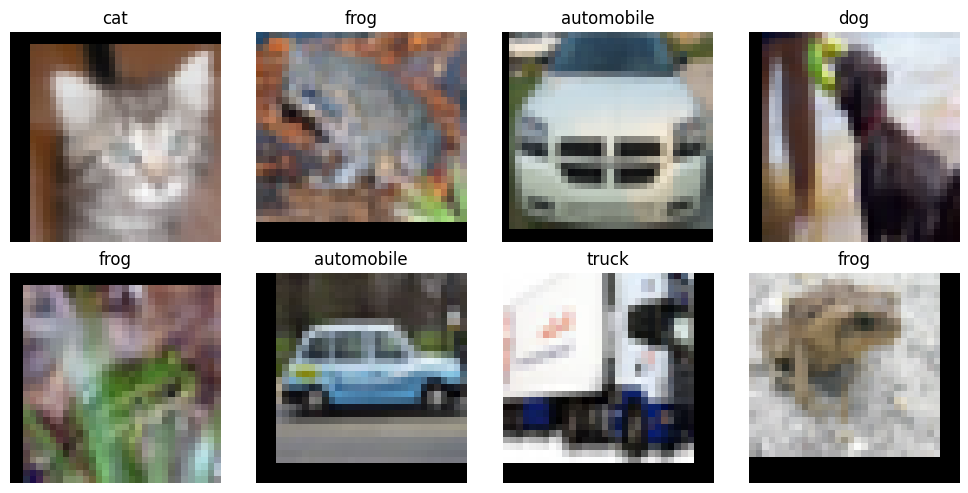

In [9]:

images, labels = next(iter(train_loader))

# Undo normalization for display
mean_tensor = torch.tensor(mean).view(1, 3, 1, 1)
std_tensor = torch.tensor(std).view(1, 3, 1, 1)

display_images = images[:8].cpu() * std_tensor + mean_tensor
display_images = display_images.clamp(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image = display_images[i].permute(1, 2, 0).numpy()
    ax.imshow(image)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()



## VGG Architecture

VGG is a Convolutional Neural Network (CNN) architecture designed for image classification.

Its main idea is to use small 3×3 convolution filters and stack multiple convolutional layers to learn increasingly complex image features.

- Early layers learn edges and simple patterns.
- Middle layers learn textures and shapes.
- Deeper layers learn more complex visual features.
- Max Pooling reduces the spatial size of feature maps.
- The final classifier predicts one of the 10 CIFAR-10 classes.

In this project, VGG-11, VGG-13 and VGG-16 will be compared, with and without Batch Normalization.


**Part 2: Building the VGG architectures.**

In [10]:

# VGG configurations adapted for CIFAR-10
VGG_CONFIGS = {
    "VGG11": [
        64, "M",
        128, "M",
        256, 256, "M",
        512, 512, "M",
        512, 512, "M"
    ],

    "VGG13": [
        64, 64, "M",
        128, 128, "M",
        256, 256, "M",
        512, 512, "M",
        512, 512, "M"
    ],

    "VGG16": [
        64, 64, "M",
        128, 128, "M",
        256, 256, 256, "M",
        512, 512, 512, "M",
        512, 512, 512, "M"
    ]
}

print("Available architectures:", list(VGG_CONFIGS.keys()))


Available architectures: ['VGG11', 'VGG13', 'VGG16']


**VGG model**

In [11]:

class VGG(nn.Module):
    def __init__(self, config, num_classes=10, batch_norm=False):
        super().__init__()

        layers = []
        in_channels = 3

        for item in config:
            if item == "M":
                # Reduce height and width by half
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))

            else:
                # Learn features using a 3x3 convolution
                layers.append(
                    nn.Conv2d(
                        in_channels,
                        item,
                        kernel_size=3,
                        padding=1
                    )
                )

                # Optionally normalize intermediate features
                if batch_norm:
                    layers.append(nn.BatchNorm2d(item))

                # Add non-linearity
                layers.append(nn.ReLU(inplace=True))

                in_channels = item

        self.features = nn.Sequential(*layers)

        # Convert the final feature maps to a fixed size
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        # Predict the 10 CIFAR-10 classes
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x


print("VGG model class defined successfully.")


VGG model class defined successfully.


**testING VGG-11 without Batch Normalization.**

In [12]:

model = VGG(
    config=VGG_CONFIGS["VGG11"],
    num_classes=10,
    batch_norm=False
).to(device)

print(model)

# Check the output shape using one batch
sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images.to(device)

with torch.no_grad():
    outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): ReLU(inplace=True)
    (13): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (14): ReLU(inplace=True)
    (15): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
 

**Trainable parameters**

In [13]:

def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

print("VGG-11 trainable parameters:",
      f"{count_parameters(model):,}")


VGG-11 trainable parameters: 9,225,610


**architecture working**

In [14]:

architecture_checks = []

for model_name, config in VGG_CONFIGS.items():
    for use_bn in [False, True]:
        test_model = VGG(
            config=config,
            num_classes=10,
            batch_norm=use_bn
        ).to(device)

        with torch.no_grad():
            test_output = test_model(sample_images)

        architecture_checks.append({
            "Model": model_name,
            "BatchNorm": use_bn,
            "Parameters": count_parameters(test_model),
            "Output shape": tuple(test_output.shape)
        })

        del test_model

architecture_table = pd.DataFrame(architecture_checks)
architecture_table


,Model,BatchNorm,Parameters,Output shape
0,VGG11,False,9225610,"(128, 10)"
1,VGG11,True,9231114,"(128, 10)"
2,VGG13,False,9410122,"(128, 10)"
3,VGG13,True,9416010,"(128, 10)"
4,VGG16,False,14719818,"(128, 10)"
5,VGG16,True,14728266,"(128, 10)"


**Part 3 — Training setup**

## 3. Training the VGG Models

In this section, we train the VGG models using the CIFAR-10 dataset.

- **Loss function:** Cross-Entropy Loss
- **Optimizer:** Stochastic Gradient Descent (SGD)
- **Momentum:** 0.9
- **Learning rate:** 0.05
- **Weight decay:** 0.0005
- **Learning-rate scheduler:** Cosine Annealing

We first test the training process with one epoch before running the complete experiments.

In [15]:
EPOCHS = 2
LEARNING_RATE = 0.05
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Epochs for initial test:", EPOCHS)

Device: cuda
Epochs for initial test: 2


In [16]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100.0 * correct / total

    return epoch_loss, epoch_accuracy


def evaluate_model(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100.0 * correct / total

    return epoch_loss, epoch_accuracy


print("Training and evaluation functions are ready.")

Training and evaluation functions are ready.


In [17]:
model = VGG(
    config=VGG_CONFIGS["VGG11"],
    num_classes=10,
    batch_norm=False
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

history = []

for epoch in range(EPOCHS):
    start_time = time.time()

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_acc = evaluate_model(
        model, val_loader, criterion
    )

    scheduler.step()

    epoch_time = time.time() - start_time

    history.append({
        "Epoch": epoch + 1,
        "Train Loss": train_loss,
        "Train Accuracy": train_acc,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_acc,
        "Time (seconds)": epoch_time
    })

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Time: {epoch_time:.1f}s"
    )

test_history = pd.DataFrame(history)
test_history

Epoch [1/2] | Train Loss: 2.2092 | Train Acc: 14.80% | Val Loss: 1.8822 | Val Acc: 26.66% | Time: 19.9s
Epoch [2/2] | Train Loss: 1.7206 | Train Acc: 34.04% | Val Loss: 1.6625 | Val Acc: 35.64% | Time: 18.7s


,Epoch,Train Loss,Train Accuracy,Validation Loss,Validation Accuracy,Time (seconds)
0,1,2.209176,14.804444,1.882244,26.66,19.948729
1,2,1.720626,34.044444,1.662548,35.64,18.739112


**Part 4 — Train all six VGG variants**

## 4. Comparing VGG Architectures With and Without Batch Normalization

We will train six models using the same CIFAR-10 dataset and training settings. The purpose is to study how network depth and Batch Normalization affect classification performance and training time.

Each experiment will record training loss, validation loss, training accuracy, validation accuracy, and epoch time.

In [18]:
EXPERIMENT_EPOCHS = 5

print("Epochs per experiment:", EXPERIMENT_EPOCHS)
print("Total experiments:", 6)
print("Total planned model-training epochs:",
      EXPERIMENT_EPOCHS * 6)

Epochs per experiment: 5
Total experiments: 6
Total planned model-training epochs: 30


In [19]:
def run_experiment(model_name, use_bn, epochs=EXPERIMENT_EPOCHS):
    print("\n" + "=" * 60)
    print(f"Model: {model_name} | BatchNorm: {use_bn}")
    print("=" * 60)

    model = VGG(
        config=VGG_CONFIGS[model_name],
        num_classes=10,
        batch_norm=use_bn
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        model.parameters(),
        lr=LEARNING_RATE,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )

    epoch_records = []

    for epoch in range(epochs):
        start_time = time.time()

        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer
        )

        val_loss, val_acc = evaluate_model(
            model, val_loader, criterion
        )

        scheduler.step()
        elapsed = time.time() - start_time

        record = {
            "Model": model_name,
            "BatchNorm": use_bn,
            "Epoch": epoch + 1,
            "Train Loss": train_loss,
            "Train Accuracy": train_acc,
            "Validation Loss": val_loss,
            "Validation Accuracy": val_acc,
            "Time (seconds)": elapsed
        }

        epoch_records.append(record)

        print(
            f"Epoch [{epoch + 1}/{epochs}] | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Acc: {val_acc:.2f}% | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

    history_df = pd.DataFrame(epoch_records)

    final_summary = {
        "Model": model_name,
        "BatchNorm": use_bn,
        "Parameters": count_parameters(model),
        "Final Train Accuracy (%)": history_df["Train Accuracy"].iloc[-1],
        "Final Validation Accuracy (%)": history_df["Validation Accuracy"].iloc[-1],
        "Final Validation Loss": history_df["Validation Loss"].iloc[-1],
        "Total Training Time (seconds)": history_df["Time (seconds)"].sum()
    }

    return model, history_df, final_summary


print("Experiment function is ready.")

Experiment function is ready.


In [20]:
test_model_bn, test_history_bn, test_summary_bn = run_experiment(
    model_name="VGG11",
    use_bn=True,
    epochs=2
)

display(test_history_bn)
display(pd.DataFrame([test_summary_bn]))


Model: VGG11 | BatchNorm: True
Epoch [1/2] | Train Acc: 15.93% | Val Acc: 20.62% | Train Loss: 2.4085 | Val Loss: 1.9253 | Time: 20.1s
Epoch [2/2] | Train Acc: 27.03% | Val Acc: 37.30% | Train Loss: 1.8203 | Val Loss: 1.6790 | Time: 18.8s


,Model,BatchNorm,Epoch,Train Loss,Train Accuracy,Validation Loss,Validation Accuracy,Time (seconds)
0,VGG11,True,1,2.408481,15.931111,1.925342,20.62,20.105910
1,VGG11,True,2,1.820291,27.028889,1.678969,37.30,18.841127


,Model,BatchNorm,Parameters,Final Train Accuracy (%),Final Validation Accuracy (%),Final Validation Loss,Total Training Time (seconds)
0,VGG11,True,9231114,27.028889,37.3,1.678969,38.947037


In [21]:
all_histories = []
all_summaries = []
trained_models = {}

for model_name in ["VGG11", "VGG13", "VGG16"]:
    for use_bn in [False, True]:
        model, history_df, summary = run_experiment(
            model_name=model_name,
            use_bn=use_bn,
            epochs=EXPERIMENT_EPOCHS
        )

        key = f"{model_name}_{'BN' if use_bn else 'NoBN'}"

        all_histories.append(history_df)
        all_summaries.append(summary)
        trained_models[key] = model

        # Release GPU memory before the next experiment
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

results_df = pd.DataFrame(all_summaries)
history_df = pd.concat(all_histories, ignore_index=True)

print("All six experiments completed.")
display(results_df)


Model: VGG11 | BatchNorm: False
Epoch [1/5] | Train Acc: 16.22% | Val Acc: 22.20% | Train Loss: 2.1686 | Val Loss: 2.1958 | Time: 18.8s
Epoch [2/5] | Train Acc: 33.95% | Val Acc: 40.74% | Train Loss: 1.7372 | Val Loss: 1.6341 | Time: 17.9s
Epoch [3/5] | Train Acc: 48.60% | Val Acc: 53.44% | Train Loss: 1.3964 | Val Loss: 1.2596 | Time: 18.9s
Epoch [4/5] | Train Acc: 59.55% | Val Acc: 62.26% | Train Loss: 1.1253 | Val Loss: 1.0497 | Time: 17.7s
Epoch [5/5] | Train Acc: 67.38% | Val Acc: 68.30% | Train Loss: 0.9134 | Val Loss: 0.8787 | Time: 17.8s

Model: VGG11 | BatchNorm: True
Epoch [1/5] | Train Acc: 20.48% | Val Acc: 31.40% | Train Loss: 2.3298 | Val Loss: 1.8154 | Time: 18.7s
Epoch [2/5] | Train Acc: 34.78% | Val Acc: 40.14% | Train Loss: 1.7211 | Val Loss: 1.6160 | Time: 17.6s
Epoch [3/5] | Train Acc: 44.14% | Val Acc: 48.92% | Train Loss: 1.4929 | Val Loss: 1.4131 | Time: 18.6s
Epoch [4/5] | Train Acc: 51.81% | Val Acc: 52.48% | Train Loss: 1.3021 | Val Loss: 1.2991 | Time: 17.6s

,Model,BatchNorm,Parameters,Final Train Accuracy (%),Final Validation Accuracy (%),Final Validation Loss,Total Training Time (seconds)
0,VGG11,False,9225610,67.380000,68.30,0.878676,91.119004
1,VGG11,True,9231114,58.240000,59.10,1.114446,91.240789
2,VGG13,False,9410122,9.842222,10.00,2.302650,103.693296
3,VGG13,True,9416010,66.773333,68.34,0.867998,106.011098
4,VGG16,False,14719818,10.071111,9.76,2.302862,114.069681
5,VGG16,True,14728266,60.691111,63.04,1.010121,124.507741


**Part 5 — Visualize the results**

*Plot training and validation accurac*

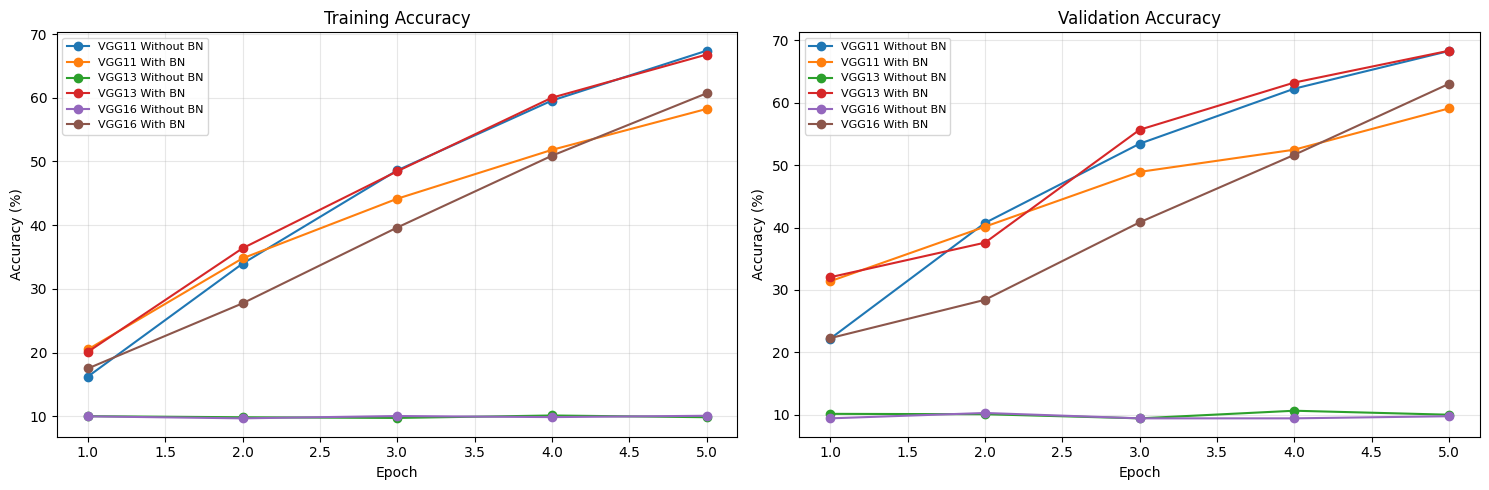

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for model_name in ["VGG11", "VGG13", "VGG16"]:
    for use_bn in [False, True]:
        subset = history_df[
            (history_df["Model"] == model_name) &
            (history_df["BatchNorm"] == use_bn)
        ]

        label = f"{model_name} {'With BN' if use_bn else 'Without BN'}"

        axes[0].plot(
            subset["Epoch"], subset["Train Accuracy"],
            marker="o", label=label
        )

        axes[1].plot(
            subset["Epoch"], subset["Validation Accuracy"],
            marker="o", label=label
        )

axes[0].set_title("Training Accuracy")
axes[1].set_title("Validation Accuracy")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

,Model,BatchNorm,Final Validation Accuracy (%),Final Validation Loss,Total Training Time (seconds)
3,VGG13,True,68.34,0.867998,106.011098
0,VGG11,False,68.30,0.878676,91.119004
5,VGG16,True,63.04,1.010121,124.507741
1,VGG11,True,59.10,1.114446,91.240789
2,VGG13,False,10.00,2.302650,103.693296
4,VGG16,False,9.76,2.302862,114.069681


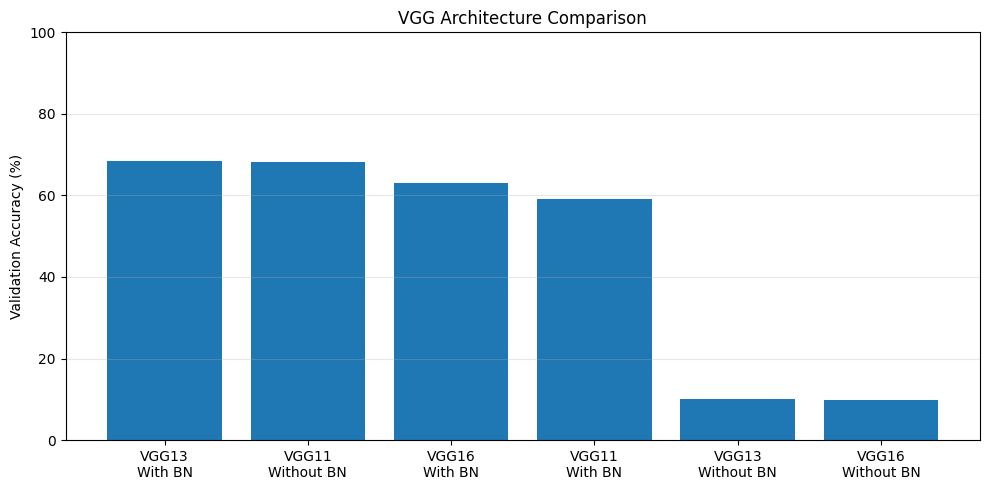

In [23]:
comparison = results_df.sort_values(
    "Final Validation Accuracy (%)",
    ascending=False
)

display(comparison[
    ["Model", "BatchNorm",
     "Final Validation Accuracy (%)",
     "Final Validation Loss",
     "Total Training Time (seconds)"]
])

plt.figure(figsize=(10, 5))

labels = [
    f"{row['Model']}\n{'With BN' if row['BatchNorm'] else 'Without BN'}"
    for _, row in comparison.iterrows()
]

plt.bar(labels, comparison["Final Validation Accuracy (%)"])
plt.ylabel("Validation Accuracy (%)")
plt.title("VGG Architecture Comparison")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
for name in ["VGG13", "VGG16"]:
    model = VGG(
        config=VGG_CONFIGS[name],
        num_classes=10,
        batch_norm=False
    ).to(device)

    print(f"\n{name} without BatchNorm")
    print("Parameters:", f"{count_parameters(model):,}")

    with torch.no_grad():
        images, labels = next(iter(val_loader))
        images = images.to(device)
        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

    print("Output mean:", outputs.mean().item())
    print("Output standard deviation:", outputs.std().item())
    print("Prediction classes:", torch.unique(predictions).tolist())
    print("Mean maximum probability:",
          probabilities.max(dim=1).values.mean().item())

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


VGG13 without BatchNorm
Parameters: 9,410,122
Output mean: 0.008383047766983509
Output standard deviation: 0.016007576137781143
Prediction classes: [5]
Mean maximum probability: 0.10300806164741516

VGG16 without BatchNorm
Parameters: 14,719,818
Output mean: -0.015194745734333992
Output standard deviation: 0.00901916902512312
Prediction classes: [8]
Mean maximum probability: 0.10196986794471741


In [25]:
display(
    history_df.groupby(["Model", "BatchNorm"])[
        ["Train Accuracy", "Validation Accuracy"]
    ].agg(["first", "last"])
)

Train Accuracy            Validation Accuracy       
                         first       last               first   last
Model BatchNorm                                                     
VGG11 False          16.220000  67.380000               22.20  68.30
      True           20.482222  58.240000               31.40  59.10
VGG13 False          10.006667   9.842222               10.14  10.00
      True           20.104444  66.773333               32.04  68.34
VGG16 False           9.980000  10.071111                9.42   9.76
      True           17.493333  60.691111               22.28  63.04

**Fix the deeper models' initialization**

In [26]:
#Kaiming initialization
def initialize_vgg(model):
    for layer in model.modules():
        if isinstance(layer, nn.Conv2d):
            nn.init.kaiming_normal_(
                layer.weight,
                mode="fan_out",
                nonlinearity="relu"
            )
            if layer.bias is not None:
                nn.init.zeros_(layer.bias)

        elif isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(
                layer.weight,
                nonlinearity="relu"
            )
            if layer.bias is not None:
                nn.init.zeros_(layer.bias)

    return model

print("Kaiming initialization function is ready.")

Kaiming initialization function is ready.


In [27]:
fixed_histories = []
fixed_summaries = []

for model_name in ["VGG13", "VGG16"]:
    print(f"\nRerunning {model_name} without BatchNorm")

    model = VGG(
        config=VGG_CONFIGS[model_name],
        num_classes=10,
        batch_norm=False
    ).to(device)

    initialize_vgg(model)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(
        model.parameters(),
        lr=LEARNING_RATE,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EXPERIMENT_EPOCHS
    )

    for epoch in range(EXPERIMENT_EPOCHS):
        start_time = time.time()

        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_acc = evaluate_model(
            model, val_loader, criterion
        )

        scheduler.step()

        fixed_histories.append({
            "Model": model_name,
            "BatchNorm": False,
            "Epoch": epoch + 1,
            "Train Loss": train_loss,
            "Train Accuracy": train_acc,
            "Validation Loss": val_loss,
            "Validation Accuracy": val_acc,
            "Time (seconds)": time.time() - start_time
        })

        print(
            f"Epoch [{epoch + 1}/{EXPERIMENT_EPOCHS}] | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Acc: {val_acc:.2f}% | "
            f"Train Loss: {train_loss:.4f}"
        )

    fixed_summaries.append({
        "Model": model_name,
        "BatchNorm": False,
        "Parameters": count_parameters(model),
        "Final Train Accuracy (%)": train_acc,
        "Final Validation Accuracy (%)": val_acc,
        "Final Validation Loss": val_loss
    })

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

fixed_history_df = pd.DataFrame(fixed_histories)
fixed_results_df = pd.DataFrame(fixed_summaries)

display(fixed_results_df)


Rerunning VGG13 without BatchNorm
Epoch [1/5] | Train Acc: 28.02% | Val Acc: 40.62% | Train Loss: 1.9043
Epoch [2/5] | Train Acc: 47.19% | Val Acc: 53.30% | Train Loss: 1.4303
Epoch [3/5] | Train Acc: 60.70% | Val Acc: 64.28% | Train Loss: 1.0960
Epoch [4/5] | Train Acc: 70.59% | Val Acc: 71.54% | Train Loss: 0.8298
Epoch [5/5] | Train Acc: 76.76% | Val Acc: 78.02% | Train Loss: 0.6607

Rerunning VGG16 without BatchNorm
Epoch [1/5] | Train Acc: 15.96% | Val Acc: 24.78% | Train Loss: 2.1946
Epoch [2/5] | Train Acc: 32.34% | Val Acc: 40.30% | Train Loss: 1.7782
Epoch [3/5] | Train Acc: 45.13% | Val Acc: 51.60% | Train Loss: 1.4742
Epoch [4/5] | Train Acc: 56.42% | Val Acc: 61.58% | Train Loss: 1.1871
Epoch [5/5] | Train Acc: 65.40% | Val Acc: 67.12% | Train Loss: 0.9580


,Model,BatchNorm,Parameters,Final Train Accuracy (%),Final Validation Accuracy (%),Final Validation Loss
0,VGG13,False,9410122,76.762222,78.02,0.639971
1,VGG16,False,14719818,65.400000,67.12,0.897061


**results with the corrected experiments**

In [28]:
# Replace the failed original runs with the corrected runs
for _, new_row in fixed_results_df.iterrows():
    mask = (
        (results_df["Model"] == new_row["Model"]) &
        (results_df["BatchNorm"] == new_row["BatchNorm"])
    )

    for column in new_row.index:
        results_df.loc[mask, column] = new_row[column]

# Update the corresponding training histories
for _, new_row in fixed_history_df.iterrows():
    mask = (
        (history_df["Model"] == new_row["Model"]) &
        (history_df["BatchNorm"] == new_row["BatchNorm"]) &
        (history_df["Epoch"] == new_row["Epoch"])
    )

    for column in new_row.index:
        history_df.loc[mask, column] = new_row[column]

display(
    results_df.sort_values(
        "Final Validation Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)
)

,Model,BatchNorm,Parameters,Final Train Accuracy (%),Final Validation Accuracy (%),Final Validation Loss,Total Training Time (seconds)
0,VGG13,False,9410122,76.762222,78.02,0.639971,103.693296
1,VGG13,True,9416010,66.773333,68.34,0.867998,106.011098
2,VGG11,False,9225610,67.380000,68.30,0.878676,91.119004
3,VGG16,False,14719818,65.400000,67.12,0.897061,114.069681
4,VGG16,True,14728266,60.691111,63.04,1.010121,124.507741
5,VGG11,True,9231114,58.240000,59.10,1.114446,91.240789


**corrected comparison**

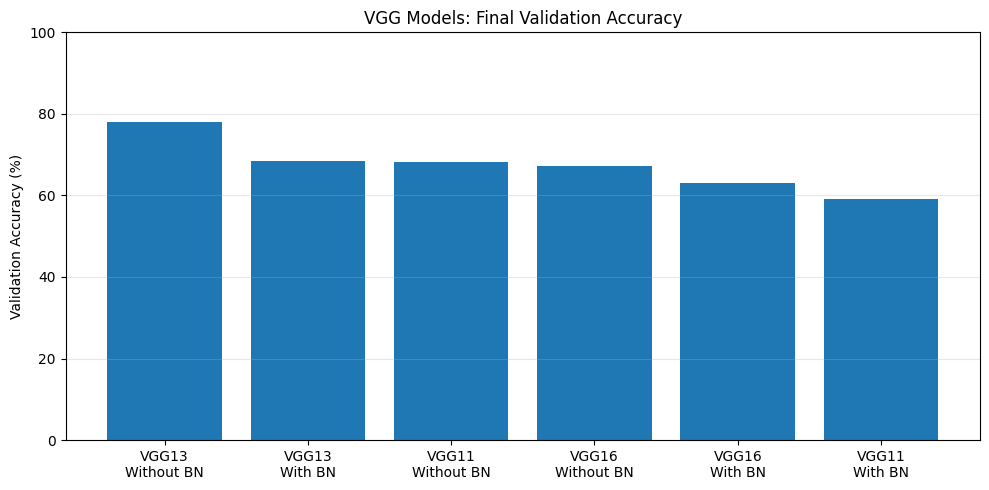

In [29]:
plt.figure(figsize=(10, 5))

plot_df = results_df.sort_values(
    "Final Validation Accuracy (%)",
    ascending=False
)

labels = [
    f"{row['Model']}\n{'With BN' if row['BatchNorm'] else 'Without BN'}"
    for _, row in plot_df.iterrows()
]

plt.bar(labels, plot_df["Final Validation Accuracy (%)"])
plt.ylabel("Validation Accuracy (%)")
plt.title("VGG Models: Final Validation Accuracy")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**evaluation function**

In [30]:
def evaluate_on_test(model, loader):
    model.eval()
    correct = 0
    total = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = 100.0 * correct / total

    return accuracy, np.array(all_labels), np.array(all_predictions)


print("Test evaluation function is ready.")

Test evaluation function is ready.


**retraining the six final models**

In [31]:
FINAL_EPOCHS = 5
final_models = {}
final_histories = []
final_summaries = []

for model_name in ["VGG11", "VGG13", "VGG16"]:
    for use_bn in [False, True]:
        key = f"{model_name}_{'BN' if use_bn else 'NoBN'}"

        print(f"\nTraining final model: {key}")

        model = VGG(
            config=VGG_CONFIGS[model_name],
            num_classes=10,
            batch_norm=use_bn
        ).to(device)

        initialize_vgg(model)

        criterion = nn.CrossEntropyLoss()
        optimizer = optim.SGD(
            model.parameters(),
            lr=LEARNING_RATE,
            momentum=MOMENTUM,
            weight_decay=WEIGHT_DECAY
        )
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=FINAL_EPOCHS
        )

        for epoch in range(FINAL_EPOCHS):
            start_time = time.time()

            train_loss, train_acc = train_one_epoch(
                model, train_loader, criterion, optimizer
            )
            val_loss, val_acc = evaluate_model(
                model, val_loader, criterion
            )

            scheduler.step()
            elapsed = time.time() - start_time

            final_histories.append({
                "Model": model_name,
                "BatchNorm": use_bn,
                "Epoch": epoch + 1,
                "Train Loss": train_loss,
                "Train Accuracy": train_acc,
                "Validation Loss": val_loss,
                "Validation Accuracy": val_acc,
                "Time (seconds)": elapsed
            })

            print(
                f"Epoch {epoch + 1}/{FINAL_EPOCHS} | "
                f"Train Acc: {train_acc:.2f}% | "
                f"Val Acc: {val_acc:.2f}%"
            )

        final_models[key] = model
        torch.save(model.state_dict(), f"{key}.pth")

        final_summaries.append({
            "Model": model_name,
            "BatchNorm": use_bn,
            "Parameters": count_parameters(model),
            "Final Validation Accuracy (%)": val_acc,
            "Final Validation Loss": val_loss
        })

final_history_df = pd.DataFrame(final_histories)
final_results_df = pd.DataFrame(final_summaries)

display(final_results_df)


Training final model: VGG11_NoBN
Epoch 1/5 | Train Acc: 36.08% | Val Acc: 49.86%
Epoch 2/5 | Train Acc: 54.50% | Val Acc: 61.92%
Epoch 3/5 | Train Acc: 65.05% | Val Acc: 67.56%
Epoch 4/5 | Train Acc: 72.74% | Val Acc: 75.94%
Epoch 5/5 | Train Acc: 78.18% | Val Acc: 78.00%

Training final model: VGG11_BN
Epoch 1/5 | Train Acc: 20.34% | Val Acc: 32.50%
Epoch 2/5 | Train Acc: 37.99% | Val Acc: 45.66%
Epoch 3/5 | Train Acc: 51.75% | Val Acc: 55.82%
Epoch 4/5 | Train Acc: 61.19% | Val Acc: 65.84%
Epoch 5/5 | Train Acc: 67.42% | Val Acc: 68.94%

Training final model: VGG13_NoBN
Epoch 1/5 | Train Acc: 25.36% | Val Acc: 40.68%
Epoch 2/5 | Train Acc: 44.05% | Val Acc: 49.18%
Epoch 3/5 | Train Acc: 57.28% | Val Acc: 63.40%
Epoch 4/5 | Train Acc: 67.70% | Val Acc: 71.14%
Epoch 5/5 | Train Acc: 74.12% | Val Acc: 75.24%

Training final model: VGG13_BN
Epoch 1/5 | Train Acc: 11.81% | Val Acc: 12.82%
Epoch 2/5 | Train Acc: 15.04% | Val Acc: 23.90%
Epoch 3/5 | Train Acc: 24.61% | Val Acc: 27.12%
Epoc

,Model,BatchNorm,Parameters,Final Validation Accuracy (%),Final Validation Loss
0,VGG11,False,9225610,78.00,0.619403
1,VGG11,True,9231114,68.94,0.865477
2,VGG13,False,9410122,75.24,0.692154
3,VGG13,True,9416010,38.94,1.568370
4,VGG16,False,14719818,70.84,0.817086
5,VGG16,True,14728266,32.48,1.720300


**Evaluate on the test set**

In [32]:
test_results = []
test_predictions = {}

for key, model in final_models.items():
    accuracy, true_labels, predictions = evaluate_on_test(
        model, test_loader
    )

    test_predictions[key] = (true_labels, predictions)

    test_results.append({
        "Experiment": key,
        "Test Accuracy (%)": accuracy
    })

test_results_df = pd.DataFrame(test_results).sort_values(
    "Test Accuracy (%)", ascending=False
)

display(test_results_df)

,Experiment,Test Accuracy (%)
0,VGG11_NoBN,77.71
2,VGG13_NoBN,75.11
4,VGG16_NoBN,70.85
1,VGG11_BN,68.96
3,VGG13_BN,39.79
5,VGG16_BN,33.32


**Part 6 — Confusion matrix and classification report**

**Confusion matrix for the best model**

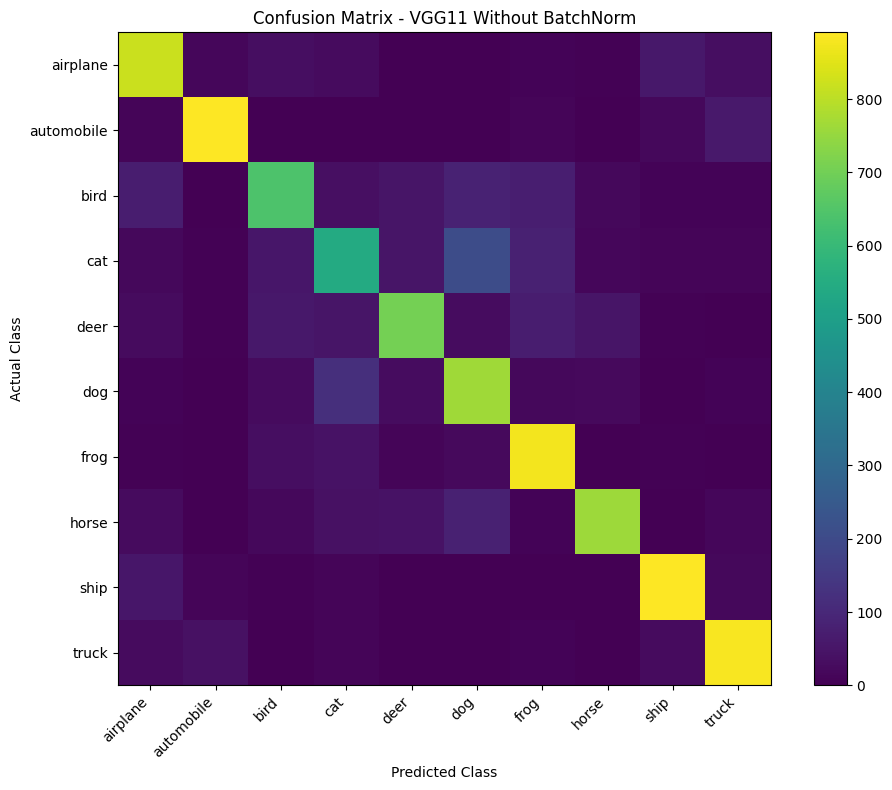

In [33]:
best_model_key = "VGG11_NoBN"

y_true, y_pred = test_predictions[best_model_key]

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix - VGG11 Without BatchNorm")
plt.colorbar()

tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45, ha="right")
plt.yticks(tick_marks, class_names)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

**Precision, recall and F1-score**

In [34]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

    airplane     0.7645    0.8180    0.7903      1000
  automobile     0.9138    0.8910    0.9023      1000
        bird     0.7354    0.6420    0.6855      1000
         cat     0.6136    0.5430    0.5761      1000
        deer     0.7871    0.7060    0.7443      1000
         dog     0.6367    0.7640    0.6945      1000
        frog     0.7543    0.8750    0.8102      1000
       horse     0.8638    0.7610    0.8091      1000
        ship     0.8697    0.8880    0.8788      1000
       truck     0.8507    0.8830    0.8665      1000

    accuracy                         0.7771     10000
   macro avg     0.7790    0.7771    0.7758     10000
weighted avg     0.7790    0.7771    0.7758     10000



**Plot the final training curves**

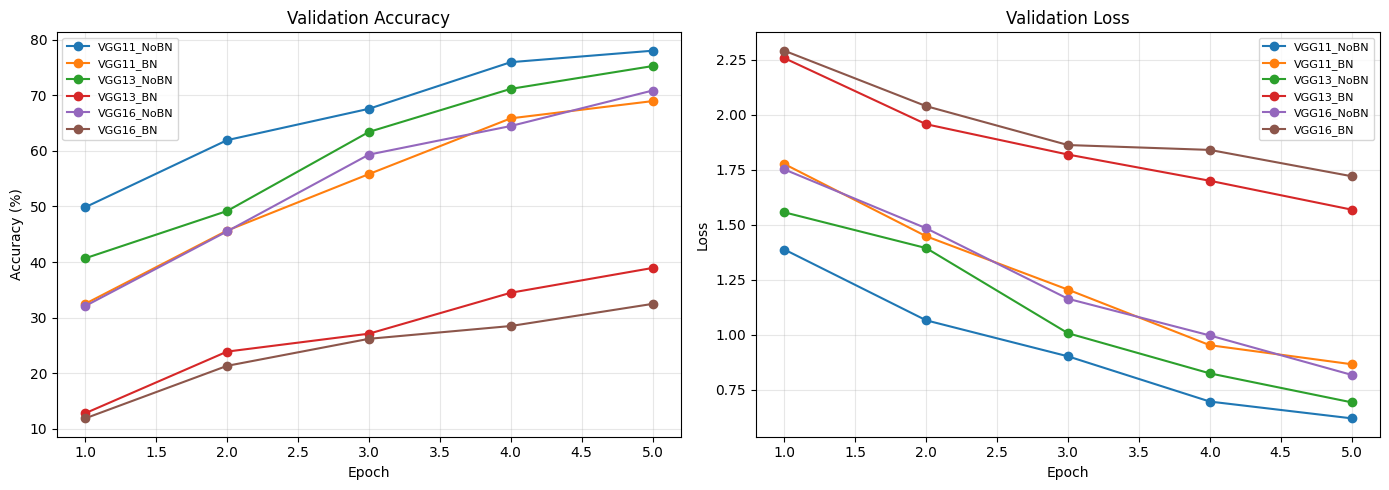

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for key in final_models:
    model_name = key.split("_")[0]
    use_bn = key.endswith("_BN")

    subset = final_history_df[
        (final_history_df["Model"] == model_name) &
        (final_history_df["BatchNorm"] == use_bn)
    ]

    axes[0].plot(
        subset["Epoch"],
        subset["Validation Accuracy"],
        marker="o",
        label=key
    )

    axes[1].plot(
        subset["Epoch"],
        subset["Validation Loss"],
        marker="o",
        label=key
    )

axes[0].set_title("Validation Accuracy")
axes[1].set_title("Validation Loss")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Accuracy (%)")
axes[1].set_ylabel("Loss")

plt.tight_layout()
plt.show()

**result save**

In [36]:
results_df.to_csv("preliminary_results.csv", index=False)
final_results_df.to_csv("final_validation_results.csv", index=False)
test_results_df.to_csv("final_test_results.csv", index=False)
final_history_df.to_csv("final_training_history.csv", index=False)

print("Result CSV files saved successfully.")

Result CSV files saved successfully.


**Part 7 — Add the project conclusion**

## 7. Conclusion

In this project, VGG-11, VGG-13, and VGG-16 were implemented using PyTorch and evaluated on the CIFAR-10 image classification dataset. Each architecture was tested with and without Batch Normalization.

In the final five-epoch experiments, VGG-11 without Batch Normalization achieved the highest test accuracy of **77.71%**. VGG-13 without Batch Normalization achieved **75.11%**, while VGG-16 without Batch Normalization achieved **70.85%**.

The confusion matrix and classification report showed that performance varied across classes. Automobile classification achieved an F1-score of 90.23%, while cat classification achieved 57.61%.

The experiments demonstrate that increasing network depth does not automatically improve performance when training time and hyperparameters are limited. Batch Normalization results also varied considerably across architectures in these runs.

**Limitations:** Each final model was trained for only five epochs. The experiments used one training run per configuration, and the Batch Normalization variants may require further tuning. The results should therefore be interpreted as preliminary rather than definitive evidence that one architecture or normalization method is universally better.

Future work could include longer training, learning-rate tuning, repeated runs with different random seeds, and a more systematic comparison of initialization strategies.